# MMFashion: DeepFashion Test Split Benchmark
### Model A (VGG-16) vs Model B (ResNet-50) — Confusion Matrix & Metrics Comparison

**ขั้นตอนการทำงาน:**
1. ✅ GPU Environment Check  
2. ✅ Clone MMFashion + Install Dependencies  
3. ✅ Mount Google Drive & Extract DeepFashion Dataset  
4. ✅ Download Pretrained Checkpoints (VGG-16 & ResNet-50)  
5. ✅ High-Speed Batch Inference on Test Split (~40,000 images)  
6. ✅ Side-by-Side 50×50 Confusion Matrix Heatmap + Top-10 Confused Pairs + CSV Report

> ⚡ **สำคัญ:** ไปที่ **Runtime > Change runtime type > T4 GPU** ก่อนรันทุกครั้ง

In [ ]:
# Step 1: Check GPU Environment
!nvidia-smi
import torch
print(f'PyTorch Version: {torch.__version__}')
print(f'CUDA Available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU Device: {torch.cuda.get_device_name(0)}')
else:
    print('WARNING: GPU not detected! Go to Runtime > Change runtime type > T4 GPU')

Tue Nov 17 03:11:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Step 2: Clone MMFashion Repository & Setup Modern Compatibility Bridge
import os, sys, types

%cd /content
if not os.path.exists('/content/mmfashion_PUNNARUST_Project'):
    !git clone https://github.com/OngarjDev/mmfashion_PUNNARUST_Project.git
else:
    print('Repo already cloned.')

%cd /content/mmfashion_PUNNARUST_Project

# Install lightweight modern dependencies
!pip install -q gdown mmcv-lite mmengine scikit-learn seaborn matplotlib tqdm pandas Pillow

# Register MMFashion to Python path
if '/content/mmfashion_PUNNARUST_Project' not in sys.path:
    sys.path.insert(0, '/content/mmfashion_PUNNARUST_Project')

# Setup backward-compatibility bridge for MMFashion on PyTorch 2.x and Pillow 10+
import mmengine
from mmengine.config import Config
from mmengine.runner import load_checkpoint
import mmcv
import torch.nn as nn
import PIL.Image

# 1. Pillow ANTIALIAS fix for newer Pillow versions (removed in Pillow 10)
if not hasattr(PIL.Image, 'ANTIALIAS'):
    PIL.Image.ANTIALIAS = PIL.Image.Resampling.LANCZOS

# 2. MMCV and MMEngine bridges
mmcv.Config = Config
mmcv.is_str = lambda x: isinstance(x, str)

if not hasattr(mmcv, 'runner'):
    mmcv.runner = types.ModuleType('mmcv.runner')
mmcv.runner.load_checkpoint = load_checkpoint
sys.modules['mmcv.runner'] = mmcv.runner

if not hasattr(mmcv, 'parallel'):
    mmcv.parallel = types.ModuleType('mmcv.parallel')
mmcv.parallel.MMDataParallel = nn.DataParallel
sys.modules['mmcv.parallel'] = mmcv.parallel

print('✅ MMFashion framework & compatibility bridge initialized successfully!')


/content
Repo already cloned.
/content/mmfashion_PUNNARUST_Project
✅ MMFashion framework & compatibility bridge initialized successfully!


In [ ]:
# Step 3: Mount Google Drive & Extract Dataset (Safe Decryption & Auto-Organize)
from google.colab import drive
import os, glob, zipfile, shutil

drive.mount('/content/drive')

target_data_dir = '/content/mmfashion_PUNNARUST_Project/data'
os.makedirs(target_data_dir, exist_ok=True)

# Find Google Drive dataset source
possible_paths = [
    '/content/drive/MyDrive/INT273',
    '/content/drive/MyDrive/datasetByOriginal',
    '/content/drive/MyDrive/DeepFashion',
]

drive_dataset_path = None
for p in possible_paths:
    if os.path.exists(p):
        drive_dataset_path = p
        break

if not drive_dataset_path:
    found = glob.glob('/content/drive/MyDrive/**/DeepFashion-*.zip', recursive=True)
    if found:
        drive_dataset_path = os.path.dirname(found[0])

print(f'📂 Dataset source directory: {drive_dataset_path}')

if drive_dataset_path and os.path.exists(drive_dataset_path):
    zip_files = sorted(glob.glob(os.path.join(drive_dataset_path, '*.zip')))
    print(f'Found {len(zip_files)} zip parts.')

    for zf in zip_files:
        bname = os.path.basename(zf)
        print(f'  Checking {bname}...')
        with zipfile.ZipFile(zf, 'r') as zip_ref:
            # Safe extraction: extract unencrypted files, bypass dummy encrypted headers
            for member in zip_ref.infolist():
                if member.flag_bits & 0x1:
                    # Skip dummy-encrypted files from other sub-benchmarks safely
                    continue
                try:
                    zip_ref.extract(member, target_data_dir)
                except Exception:
                    pass

    # Standardize folder structure for MMFashion Attr_Predict
    src_attr = os.path.join(target_data_dir, 'DeepFashion/Category and Attribute Prediction Benchmark')
    dst_attr = os.path.join(target_data_dir, 'Attr_Predict')
    if os.path.exists(src_attr) and not os.path.exists(dst_attr):
        shutil.move(src_attr, dst_attr)
        print('✅ Reorganized: Attr_Predict folder ready')

    # Symlink img to Attr_Predict/Img
    img_src = os.path.join(target_data_dir, 'img')
    img_dst = os.path.join(dst_attr, 'Img')
    if os.path.exists(img_src) and not os.path.exists(img_dst):
        os.symlink(img_src, img_dst)
        print('✅ Symlinked img/ -> Attr_Predict/Img/')

    # Double-nested symlink for dataset path convention: data/Attr_Predict/Img/img/...
    if os.path.exists(img_src) and not os.path.exists(os.path.join(img_src, 'img')):
        os.symlink(img_src, os.path.join(img_src, 'img'))
        print('✅ Symlinked data/img/img -> data/img (resolves Img/img/... paths)')

    # Copy vgg16 backbone weight if present
    vgg_src = os.path.join(drive_dataset_path, 'vgg16-397923af.pth')
    if os.path.exists(vgg_src):
        cache_dir = os.path.expanduser('~/.cache/torch/hub/checkpoints')
        os.makedirs(cache_dir, exist_ok=True)
        shutil.copy(vgg_src, os.path.join(cache_dir, 'vgg16-397923af.pth'))
        print('✅ Cached vgg16 backbone weight')

    print('\n🎉 Dataset extraction and organization complete!')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Dataset source directory: /content/drive/MyDrive/INT273
Found 16 zip parts.
  Checking DeepFashion-20261111T031711Z-1-003.zip...
  Checking DeepFashion-20261111T031711Z-1-004.zip...
  Checking DeepFashion-20261111T031711Z-1-008.zip...
  Checking DeepFashion-20261111T031711Z-1-009.zip...
  Checking DeepFashion-20261111T031711Z-1-011.zip...
  Checking DeepFashion-20261111T031711Z-1-013.zip...
  Checking DeepFashion-20261111T031711Z-1-014.zip...
  Checking DeepFashion-20261111T031711Z-1-015.zip...
  Checking DeepFashion-20261111T031711Z-1-016.zip...
  Checking DeepFashion-20261111T031711Z-1-017.zip...
  Checking DeepFashion-20261111T031711Z-1-018.zip...
  Checking img-001.zip...
  Checking img-005.zip...
  Checking img-010.zip...
  Checking img_highres-006.zip...
  Checking img_highres_seg-019.zip...
✅ Cached vgg16 backbone weight

🎉 Dataset extraction and org

In [ ]:
# Step 4: Download Pretrained Model Checkpoints
import gdown

ckpt_base = '/content/mmfashion_PUNNARUST_Project/checkpoint/CateAttrPredict'
os.makedirs(f'{ckpt_base}/vgg/global', exist_ok=True)
os.makedirs(f'{ckpt_base}/resnet/global', exist_ok=True)

# Model A: VGG-16 (Fine-grained Category & Attribute Predictor)
vgg_ckpt = f'{ckpt_base}/vgg/global/latest.pth'
if not os.path.exists(vgg_ckpt):
    print('Downloading Model A (VGG-16)...')
    gdown.download(id='10SZ3Lw4U0F9OKAuHWc-tBbvLS6yfE_x8', output=vgg_ckpt, quiet=False)
else:
    print(f'Model A already cached: {vgg_ckpt}')

# Model B: ResNet-50 (Fine-grained Category & Attribute Predictor)
resnet_ckpt = f'{ckpt_base}/resnet/global/latest.pth'
if not os.path.exists(resnet_ckpt):
    print('Downloading Model B (ResNet-50)...')
    gdown.download(id='1zsgxJAkdumpw4uDkapb1Ulq-aG1Hwz45', output=resnet_ckpt, quiet=False)
else:
    print(f'Model B already cached: {resnet_ckpt}')

print(f'\nModel A (VGG-16):   {os.path.getsize(vgg_ckpt)/1e6:.1f} MB')
print(f'Model B (ResNet-50): {os.path.getsize(resnet_ckpt)/1e6:.1f} MB')

Downloading...
From (original): https://drive.google.com/uc?id=10SZ3Lw4U0F9OKAuHWc-tBbvLS6yfE_x8
From (redirected): https://drive.google.com/uc?id=10SZ3Lw4U0F9OKAuHWc-tBbvLS6yfE_x8&confirm=t&uuid=c42250cf-04f3-45f5-9d65-44e2c4d9db96
To: /content/mmfashion_PUNNARUST_Project/checkpoint/CateAttrPredict/vgg/global/latest.pth
100%|██████████| 332M/332M [00:03<00:00, 85.3MB/s]


Downloading...
From (original): https://drive.google.com/uc?id=1zsgxJAkdumpw4uDkapb1Ulq-aG1Hwz45
From (redirected): https://drive.google.com/uc?id=1zsgxJAkdumpw4uDkapb1Ulq-aG1Hwz45&confirm=t&uuid=05b06ea4-ac3f-496d-b8f7-a579eeab7eb0
To: /content/mmfashion_PUNNARUST_Project/checkpoint/CateAttrPredict/resnet/global/latest.pth
100%|██████████| 1.36G/1.36G [00:16<00:00, 80.6MB/s]


Model A (VGG-16):   332.3 MB
Model B (ResNet-50): 1364.1 MB


In [20]:
# Step 5: High-Speed Batch Inference on Test Split (Save Probabilities & Image Paths)
import torch, numpy as np, time
import PIL.Image
from tqdm import tqdm
from mmengine.config import Config
from mmcv.runner import load_checkpoint
from mmfashion.datasets.utils import get_dataset
from mmfashion.datasets import build_dataloader
from mmfashion.models import build_predictor

# Ensure PIL.Image.ANTIALIAS is defined
if not hasattr(PIL.Image, 'ANTIALIAS'):
    PIL.Image.ANTIALIAS = PIL.Image.Resampling.LANCZOS

def worker_init_fn(worker_id):
    import PIL.Image
    if not hasattr(PIL.Image, 'ANTIALIAS'):
        PIL.Image.ANTIALIAS = PIL.Image.Resampling.LANCZOS

# Load configs
cfg_vgg = Config.fromfile('configs/category_attribute_predict/global_predictor_vgg.py', lazy_import=False)
cfg_resnet = Config.fromfile('configs/category_attribute_predict/roi_predictor_resnet.py', lazy_import=False)

cfg_vgg.model.pretrained = None
cfg_resnet.model.pretrained = None

# Optimize batch for Colab GPU
cfg_vgg.data.imgs_per_gpu = 64
cfg_vgg.data.workers_per_gpu = 2

# Load Test Dataset
print('📦 Loading DeepFashion Test Split Dataset...')
test_dataset = get_dataset(cfg_vgg.data.test)
dataloader = build_dataloader(
    test_dataset, imgs_per_gpu=cfg_vgg.data.imgs_per_gpu,
    workers_per_gpu=cfg_vgg.data.workers_per_gpu,
    num_gpus=1, dist=False, shuffle=False
)
dataloader.worker_init_fn = worker_init_fn

total = len(test_dataset)
test_img_paths = [test_dataset.img_list[i] for i in range(total)]
print(f'✅ Successfully loaded Test Dataset: {total:,} images')

def evaluate_model(config, ckpt_path, name):
    print(f'\n🚀 Evaluating {name}...')
    model = build_predictor(config.model)
    load_checkpoint(model, ckpt_path, map_location='cpu')
    model = model.cuda().eval()

    preds, probs, targets = [], [], []
    top3_ok = top5_ok = 0
    t0 = time.time()

    with torch.no_grad():
        for batch in tqdm(dataloader, desc=name):
            imgs = batch['img'].cuda()
            landmark = batch['landmark'].cuda()
            attr = batch['attr'].cuda()
            cate = batch['cate'].numpy().flatten()

            _, cate_pred = model(imgs, attr, landmark=landmark, return_loss=False)
            pred_prob = torch.softmax(cate_pred, dim=1).data.cpu().numpy()

            top1 = np.argmax(pred_prob, axis=1)
            preds.extend(top1)
            probs.extend(pred_prob)
            targets.extend(cate)

            sorted_idx = np.argsort(pred_prob, axis=1)[:, ::-1]
            for i, t in enumerate(cate):
                if t in sorted_idx[i, :3]: top3_ok += 1
                if t in sorted_idx[i, :5]: top5_ok += 1

    elapsed = time.time() - t0
    fps = total / elapsed
    print(f'⏱️ Done in {elapsed:.1f}s | {fps:.0f} img/s')
    return np.array(preds), np.array(probs), np.array(targets), top3_ok/total, top5_ok/total, fps

pred_vgg, probs_vgg, targets, top3_vgg, top5_vgg, fps_vgg = evaluate_model(cfg_vgg, vgg_ckpt, 'Model A: VGG-16 Global')
pred_resnet, probs_resnet, _, top3_resnet, top5_resnet, fps_resnet = evaluate_model(cfg_resnet, resnet_ckpt, 'Model B: ResNet-50 RoI')

print('\n🎉 Inference complete for both models!')


📦 Loading DeepFashion Test Split Dataset...
✅ Successfully loaded Test Dataset: 4,000 images

🚀 Evaluating Model A: VGG-16 Global...
pretrained model None
Loads checkpoint by local backend from path: /content/mmfashion_PUNNARUST_Project/checkpoint/CateAttrPredict/vgg/global/latest.pth


Model A: VGG-16 Global: 100%|██████████| 63/63 [00:23<00:00,  2.65it/s]


⏱️ Done in 23.8s | 168 img/s

🚀 Evaluating Model B: ResNet-50 RoI...
pretrained model None
Loads checkpoint by local backend from path: /content/mmfashion_PUNNARUST_Project/checkpoint/CateAttrPredict/resnet/global/latest.pth


Model B: ResNet-50 RoI:   0%|          | 0/63 [00:00<?, ?it/s]/content/mmfashion_PUNNARUST_Project/mmfashion/models/roi_pool/roi_pooling.py:66: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  flowfield = nn.functional.affine_grid(theta, size)
/content/mmfashion_PUNNARUST_Project/mmfashion/models/roi_pool/roi_pooling.py:67: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for details.
  one_pooled = nn.functional.grid_sample(
Model B: ResNet-50 RoI: 100%|██████████| 63/63 [00:20<00:00,  3.11it/s]

⏱️ Done in 20.3s | 197 img/s

🎉 Inference complete for both models!



  🏆 DEEPFASHION BENCHMARK RESULTS (TEST SPLIT)
Evaluation Metric Model A (VGG-16 Global) Model B (ResNet-50 RoI)
   Top-1 Accuracy                  45.42%                  51.23%
   Top-3 Accuracy                  70.45%                  77.03%
   Top-5 Accuracy                  81.90%                  86.10%
   Macro F1-Score                  0.1134                  0.1731
Weighted F1-Score                  0.3842                  0.4638
    Macro ROC-AUC                  0.7768                  0.8363
    Micro ROC-AUC                  0.9313                  0.9403
       Throughput               168 img/s               197 img/s

💾 Saved high-res Confusion Matrix plot to: /content/drive/MyDrive/MMFashion_Evaluation_Results/confusion_matrix_comparison.png


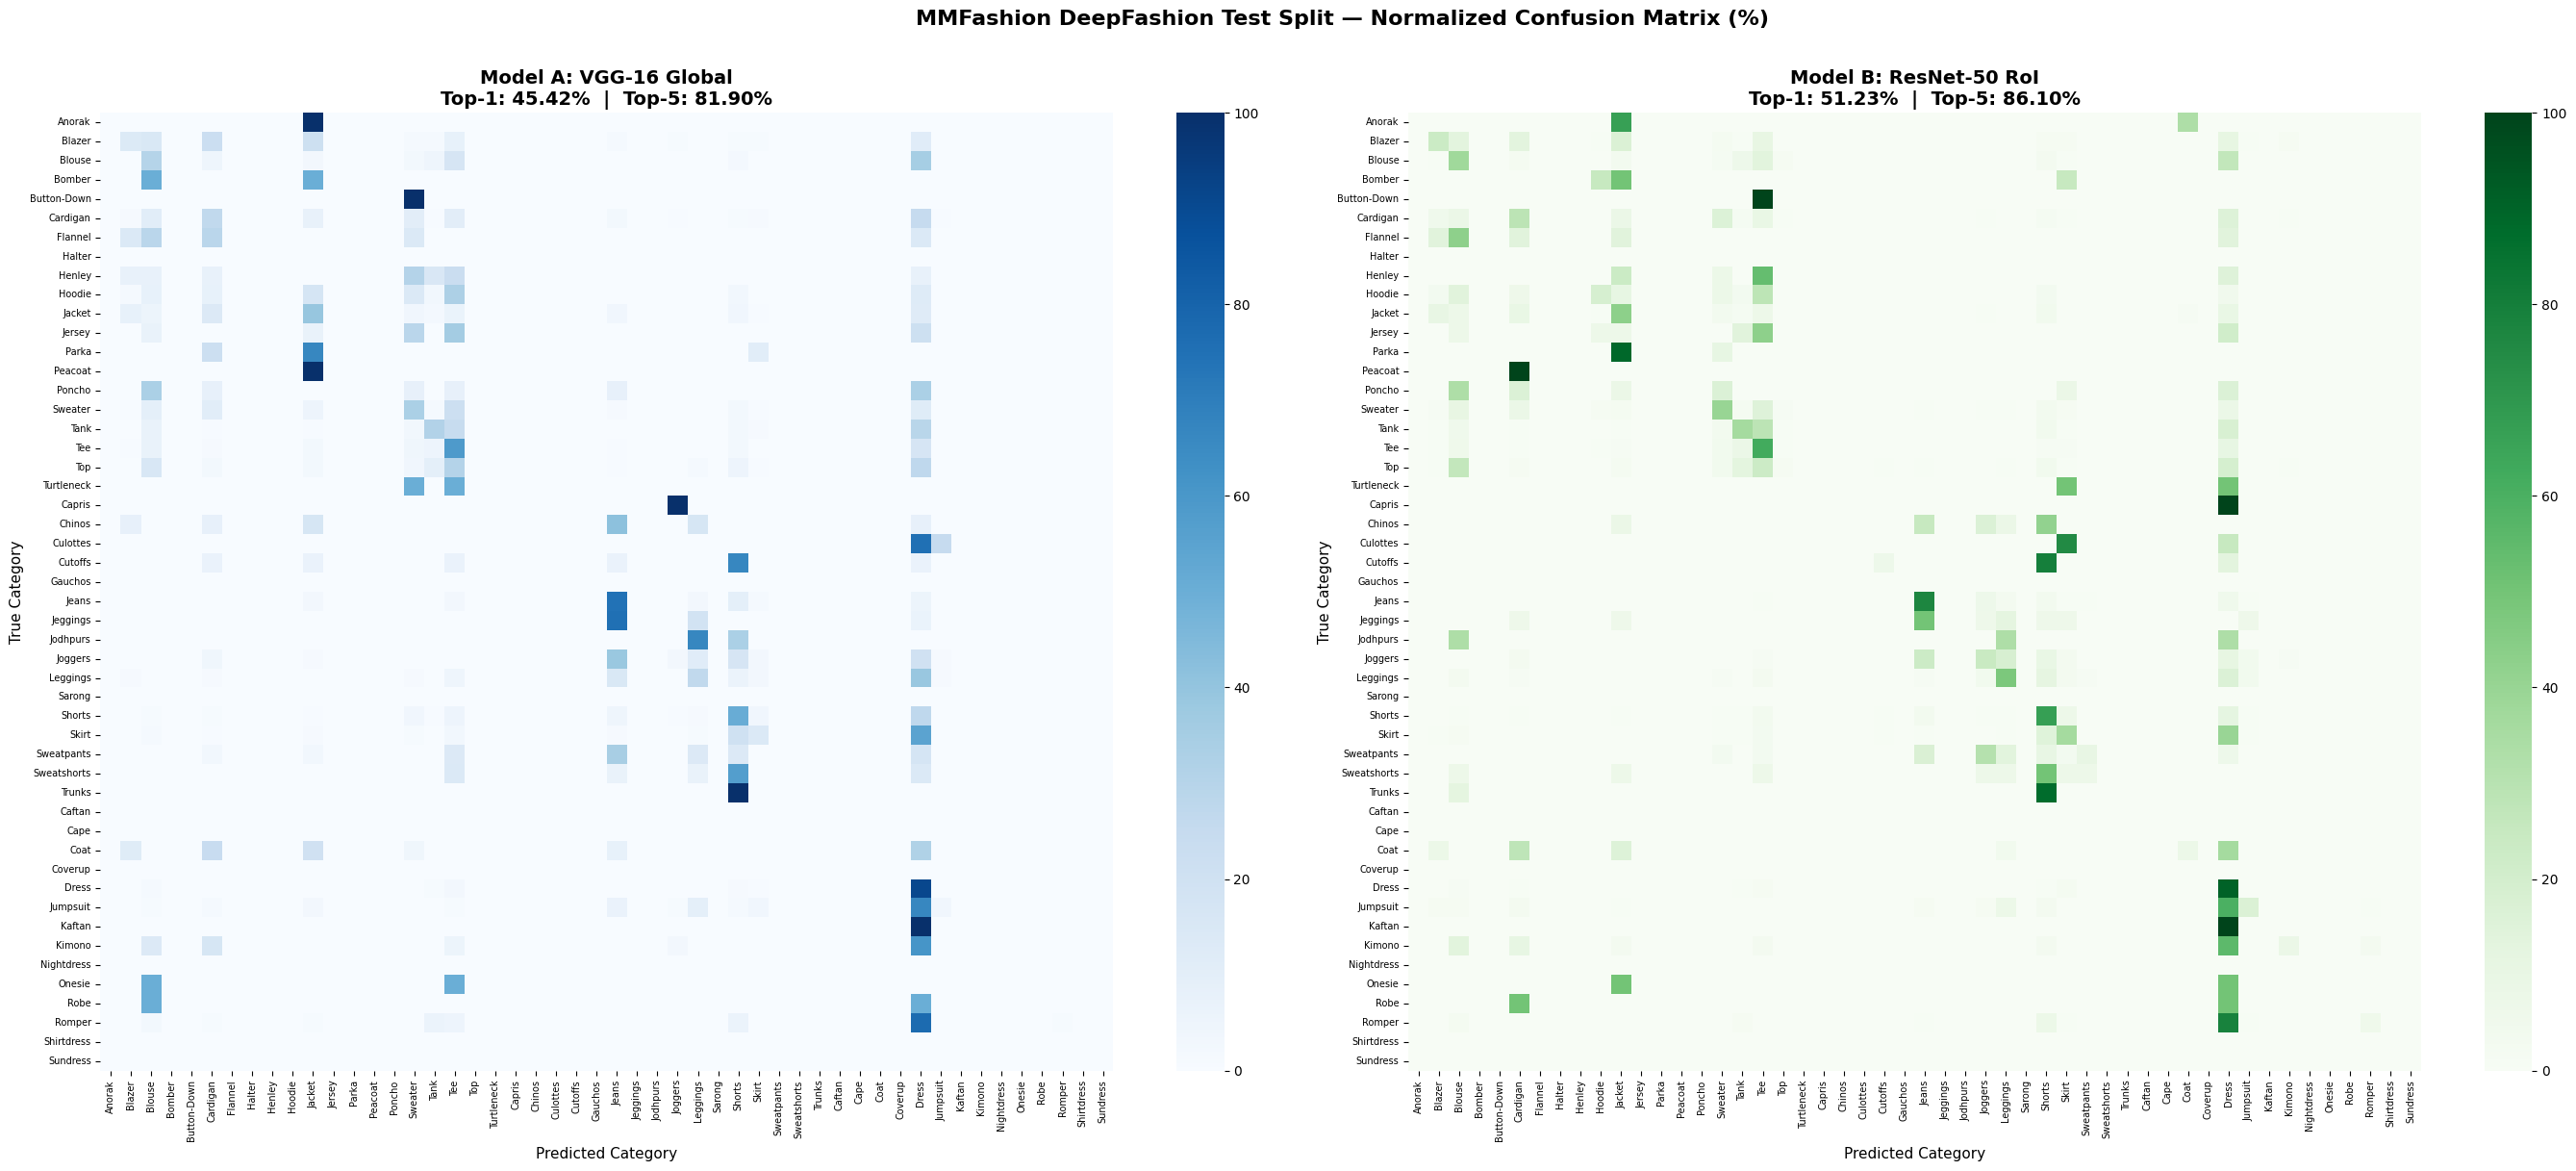

💾 Saved high-res ROC Curves plot to: /content/drive/MyDrive/MMFashion_Evaluation_Results/roc_curves_comparison.png


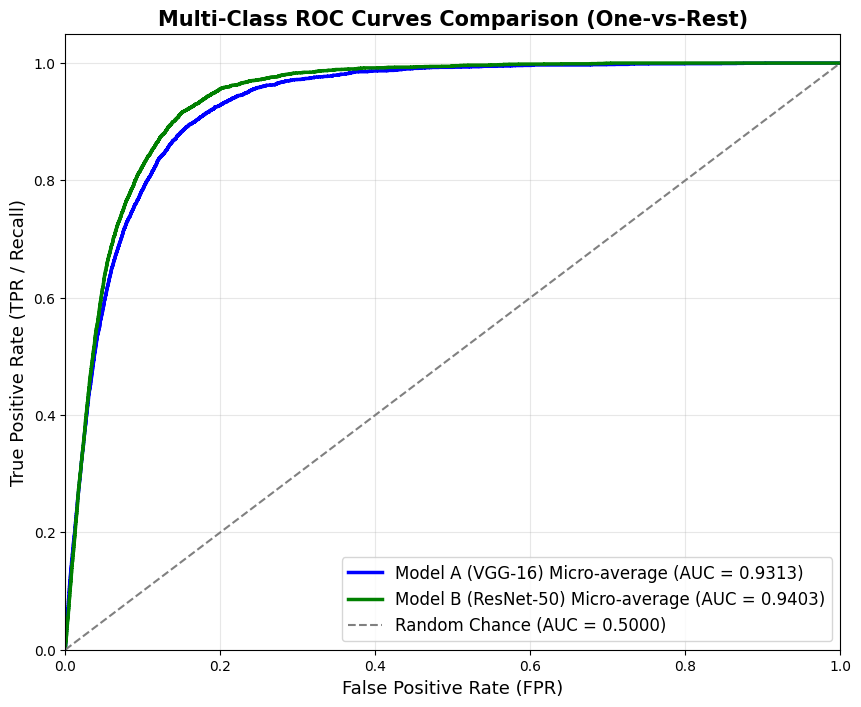


✅ All reports and plots successfully saved to: /content/drive/MyDrive/MMFashion_Evaluation_Results


In [22]:
# Step 6: Confusion Matrix, Multi-Class ROC-AUC & Benchmark Report
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Save results to Google Drive
results_dir = '/content/drive/MyDrive/MMFashion_Evaluation_Results'
os.makedirs(results_dir, exist_ok=True)

# Load 50 category class names
cate_path = 'data/Attr_Predict/Anno_fine/list_category_cloth.txt'
cat_names = []
if os.path.exists(cate_path):
    with open(cate_path) as f:
        for line in f.readlines()[2:]:
            parts = line.strip().split()
            if parts:
                cat_names.append(' '.join(parts[:-1]))
else:
    cat_names = [f'Cat_{i}' for i in range(50)]
n_classes = len(cat_names)
all_labels = list(range(n_classes))

# 1. Compute Accuracy and F1 Metrics
acc_v  = accuracy_score(targets, pred_vgg)
acc_r  = accuracy_score(targets, pred_resnet)
f1m_v  = f1_score(targets, pred_vgg,    average='macro',    zero_division=0)
f1m_r  = f1_score(targets, pred_resnet, average='macro',    zero_division=0)
f1w_v  = f1_score(targets, pred_vgg,    average='weighted', zero_division=0)
f1w_r  = f1_score(targets, pred_resnet, average='weighted', zero_division=0)

# 2. Compute Multi-Class ROC-AUC (One-vs-Rest)
y_one_hot = label_binarize(targets, classes=all_labels)
present_classes = np.unique(targets)
y_present = label_binarize(targets, classes=present_classes)

roc_auc_macro_v = roc_auc_score(y_present, probs_vgg[:, present_classes], average='macro')
roc_auc_macro_r = roc_auc_score(y_present, probs_resnet[:, present_classes], average='macro')

roc_auc_micro_v = roc_auc_score(y_one_hot, probs_vgg, average='micro')
roc_auc_micro_r = roc_auc_score(y_one_hot, probs_resnet, average='micro')

# 3. Summary Comparison Table
summary = pd.DataFrame({
    'Evaluation Metric': [
        'Top-1 Accuracy', 'Top-3 Accuracy', 'Top-5 Accuracy',
        'Macro F1-Score', 'Weighted F1-Score',
        'Macro ROC-AUC', 'Micro ROC-AUC', 'Throughput'
    ],
    'Model A (VGG-16 Global)': [
        f'{acc_v*100:.2f}%', f'{top3_vgg*100:.2f}%', f'{top5_vgg*100:.2f}%',
        f'{f1m_v:.4f}', f'{f1w_v:.4f}',
        f'{roc_auc_macro_v:.4f}', f'{roc_auc_micro_v:.4f}', f'{fps_vgg:.0f} img/s'
    ],
    'Model B (ResNet-50 RoI)': [
        f'{acc_r*100:.2f}%', f'{top3_resnet*100:.2f}%', f'{top5_resnet*100:.2f}%',
        f'{f1m_r:.4f}', f'{f1w_r:.4f}',
        f'{roc_auc_macro_r:.4f}', f'{roc_auc_micro_r:.4f}', f'{fps_resnet:.0f} img/s'
    ],
})
print('\n' + '='*75)
print('  🏆 DEEPFASHION BENCHMARK RESULTS (TEST SPLIT)')
print('='*75)
print(summary.to_string(index=False))
summary.to_csv(f'{results_dir}/summary_metrics.csv', index=False)

# 4. Normalized Confusion Matrices (0 - 100%)
cm_v = confusion_matrix(targets, pred_vgg,    labels=all_labels, normalize='true') * 100
cm_r = confusion_matrix(targets, pred_resnet, labels=all_labels, normalize='true') * 100

fig, axes = plt.subplots(1, 2, figsize=(28, 12))
for ax, cm, cmap, name, acc, top5 in [
    (axes[0], cm_v, 'Blues',  'Model A: VGG-16 Global',   acc_v, top5_vgg),
    (axes[1], cm_r, 'Greens', 'Model B: ResNet-50 RoI',   acc_r, top5_resnet),
]:
    sns.heatmap(cm, ax=ax, cmap=cmap, fmt='.1f', cbar=True,
                xticklabels=cat_names, yticklabels=cat_names)
    ax.set_title(f'{name}\nTop-1: {acc*100:.2f}%  |  Top-5: {top5*100:.2f}%', fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted Category', fontsize=11)
    ax.set_ylabel('True Category', fontsize=11)
    ax.tick_params(axis='x', rotation=90, labelsize=7)
    ax.tick_params(axis='y', rotation=0,  labelsize=7)
plt.suptitle('MMFashion DeepFashion Test Split — Normalized Confusion Matrix (%)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
cm_save_path = f'{results_dir}/confusion_matrix_comparison.png'
fig.savefig(cm_save_path, dpi=300, bbox_inches='tight')
print(f'\n💾 Saved high-res Confusion Matrix plot to: {cm_save_path}')
plt.show()

# 5. Multi-Class ROC Curves Plot (One-vs-Rest Micro & Macro)
fpr_micro_v, tpr_micro_v, _ = roc_curve(y_one_hot.ravel(), probs_vgg.ravel())
fpr_micro_r, tpr_micro_r, _ = roc_curve(y_one_hot.ravel(), probs_resnet.ravel())

plt.figure(figsize=(10, 8))
plt.plot(fpr_micro_v, tpr_micro_v, color='blue', lw=2.5,
         label=f'Model A (VGG-16) Micro-average (AUC = {roc_auc_micro_v:.4f})')
plt.plot(fpr_micro_r, tpr_micro_r, color='green', lw=2.5,
         label=f'Model B (ResNet-50) Micro-average (AUC = {roc_auc_micro_r:.4f})')
plt.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.5000)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=13)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=13)
plt.title('Multi-Class ROC Curves Comparison (One-vs-Rest)', fontsize=15, fontweight='bold')
plt.legend(loc='lower right', fontsize=12)
plt.grid(True, alpha=0.3)
roc_save_path = f'{results_dir}/roc_curves_comparison.png'
plt.savefig(roc_save_path, dpi=300, bbox_inches='tight')
print(f'💾 Saved high-res ROC Curves plot to: {roc_save_path}')
plt.show()

# 6. Top-10 Most Confused Category Pairs
def top_confusions(cm, names, n=10):
    pairs = [(names[i], names[j], cm[i,j]) for i in range(len(names)) for j in range(len(names)) if i != j and not np.isnan(cm[i,j])]
    pairs.sort(key=lambda x: x[2], reverse=True)
    return pd.DataFrame(pairs[:n], columns=['True Category', 'Predicted As', 'Error Rate (%)'])

df_conf_v = top_confusions(cm_v, cat_names)
df_conf_r = top_confusions(cm_r, cat_names)
df_conf_v.to_csv(f'{results_dir}/top_confused_pairs_vgg16.csv', index=False)
df_conf_r.to_csv(f'{results_dir}/top_confused_pairs_resnet50.csv', index=False)

# 7. Per-Class Classification Report
report_v = classification_report(targets, pred_vgg,    labels=all_labels, target_names=cat_names, output_dict=True, zero_division=0)
report_r = classification_report(targets, pred_resnet, labels=all_labels, target_names=cat_names, output_dict=True, zero_division=0)
pd.DataFrame(report_v).T.to_csv(f'{results_dir}/per_class_report_vgg16.csv')
pd.DataFrame(report_r).T.to_csv(f'{results_dir}/per_class_report_resnet50.csv')

print(f'\n✅ All reports and plots successfully saved to: {results_dir}')


In [23]:
# Step 7: Interactive Gallery (Correct vs Incorrect Predictions per Class)
import ipywidgets as widgets
from IPython.display import display, clear_output
import PIL.Image
import matplotlib.pyplot as plt
import os

# Base directory for images
img_base_dir = '/content/mmfashion_PUNNARUST_Project/data/Attr_Predict/Img'

# Pre-index indices for Correct and Incorrect predictions per class
def build_prediction_index(predictions, ground_truth, n_cls):
    correct_idx = {c: [] for c in range(n_cls)}
    incorrect_idx = {c: [] for c in range(n_cls)}
    for i, (p, g) in enumerate(zip(predictions, ground_truth)):
        if p == g:
            correct_idx[g].append(i)
        else:
            incorrect_idx[g].append(i)
    return correct_idx, incorrect_idx

idx_vgg_corr, idx_vgg_inc = build_prediction_index(pred_vgg, targets, n_classes)
idx_res_corr, idx_res_inc = build_prediction_index(pred_resnet, targets, n_classes)

# UI Widgets
model_dropdown = widgets.Dropdown(
    options=[('Model A: VGG-16 Global', 'vgg'), ('Model B: ResNet-50 RoI', 'resnet')],
    value='resnet',
    description='Model:',
    style={'description_width': 'initial'}
)

type_radio = widgets.RadioButtons(
    options=[('✅ Correct Predictions (ทายถูก)', 'correct'), ('❌ Incorrect Predictions (ทายผิด)', 'incorrect')],
    value='incorrect',
    description='Result Type:',
    style={'description_width': 'initial'}
)

class_dropdown = widgets.Dropdown(
    options=[(f"{i}: {name}", i) for i, name in enumerate(cat_names)],
    value=0,
    description='Category:',
    style={'description_width': 'initial'}
)

num_slider = widgets.IntSlider(
    value=10, min=1, max=20, step=1,
    description='Num Images:',
    style={'description_width': 'initial'}
)

gallery_out = widgets.Output()

def update_gallery(*args):
    with gallery_out:
        clear_output(wait=True)
        m = model_dropdown.value
        t_type = type_radio.value
        cls_id = class_dropdown.value
        n_show = num_slider.value
        cls_name = cat_names[cls_id]

        if m == 'vgg':
            active_idx = idx_vgg_corr[cls_id] if t_type == 'correct' else idx_vgg_inc[cls_id]
            pred_arr = pred_vgg
            prob_arr = probs_vgg
            m_label = 'VGG-16 Global'
        else:
            active_idx = idx_res_corr[cls_id] if t_type == 'correct' else idx_res_inc[cls_id]
            pred_arr = pred_resnet
            prob_arr = probs_resnet
            m_label = 'ResNet-50 RoI'

        total_avail = len(active_idx)
        print(f"📊 {m_label} | {cls_name} ({t_type.upper()}) | Found: {total_avail} images")

        if total_avail == 0:
            print("✨ No samples found for this category and filter.")
            return

        selected_idx = active_idx[:n_show]
        ncols = 5
        nrows = (len(selected_idx) + ncols - 1) // ncols

        fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4.5 * nrows))
        if nrows == 1 and ncols == 1:
            axes = np.array([axes])
        axes = np.array(axes).flatten()

        for k, sample_i in enumerate(selected_idx):
            rel_path = test_img_paths[sample_i]
            full_path = os.path.join(img_base_dir, rel_path)
            true_label = cat_names[targets[sample_i]]
            pred_label = cat_names[pred_arr[sample_i]]
            conf = prob_arr[sample_i][pred_arr[sample_i]] * 100

            ax = axes[k]
            if os.path.exists(full_path):
                img = PIL.Image.open(full_path).convert('RGB')
                ax.imshow(img)
            else:
                ax.text(0.5, 0.5, "Image not found", ha='center', va='center')

            color = 'green' if true_label == pred_label else 'red'
            title = f"True: {true_label}\nPred: {pred_label}\n({conf:.1f}%)"
            ax.set_title(title, fontsize=10, color=color, fontweight='bold')
            ax.axis('off')

        # Hide any unused subplots
        for k in range(len(selected_idx), len(axes)):
            axes[k].axis('off')

        plt.tight_layout()
        plt.show()

model_dropdown.observe(update_gallery, names='value')
type_radio.observe(update_gallery, names='value')
class_dropdown.observe(update_gallery, names='value')
num_slider.observe(update_gallery, names='value')

ui_box = widgets.VBox([
    widgets.HTML("<h3>🖼️ Interactive Model Prediction Visualizer & Gallery</h3>"),
    widgets.HBox([model_dropdown, type_radio]),
    widgets.HBox([class_dropdown, num_slider]),
    gallery_out
])

display(ui_box)
update_gallery()
